# Cleaning and weekly aggregation

Apply the project cleaning rules in memory and compare them with the archived audit.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd().resolve()
NB = HERE if (HERE / 'mandi_notes.py').is_file() else HERE / 'Notebook'
sys.path.insert(0, str(NB))
from mandi_notes import *

,Rows in bounded sample
raw_records,25000
usable_records,24714
duplicate_records,3
conflicting_records,0
anomalous_records,283
invalid_key_records,0
review_records,15


,input,normalized
0,soybean,Soyabean
1,Uttrakhand,UK
2,Market Name,Market Name


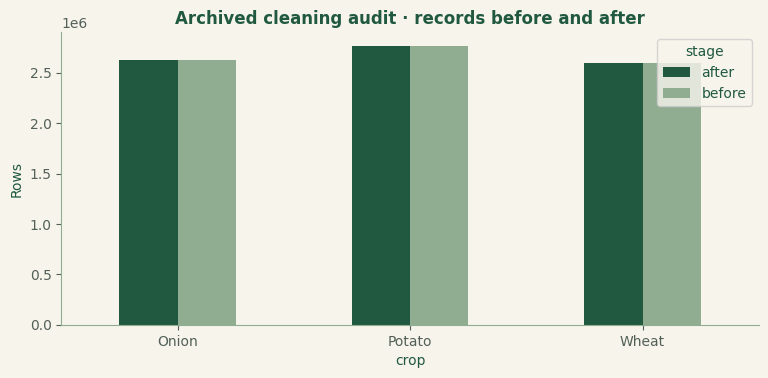

In [2]:
from Code.daily.dataset import MANDI_COLUMNS, clean_prices
from Code.daily.policy import KEY, commodity, text
from Code.intelligence.states import state_id
from Code.utils.data_audit import load_mandi_file, parse_dates_fast

raw = load_mandi_file("Onion.csv", mandi_dir=RAW, nrows=25000).rename(columns=MANDI_COLUMNS)
raw["reported_date"] = parse_dates_fast(raw.reported_date)
for key in KEY + ["commodity_group"]:
    raw[key] = raw[key].map(lambda value: text(value) if pd.notna(value) and text(value) else None).astype("category")
raw["source_row"], raw["crop"] = np.arange(len(raw)), "Onion"
clean, counts = clean_prices(raw)
clean = clean.loc[~clean.duplicated(KEY + ["reported_date"], keep=False)].copy()
display(pd.Series(counts, name="Rows in bounded sample").to_frame())
display(pd.DataFrame({"input": ["soybean", "Uttrakhand", "  Market   Name  "],
                      "normalized": [commodity("soybean"), state_id("Uttrakhand"), text("  Market   Name  ")]}))
audit = pd.read_csv(DATA / "cleaning_audit/quality_metrics_before_after.csv")
audit.query("metric == 'rows'").assign(value=lambda x: pd.to_numeric(x.value)).pivot(index="crop", columns="stage", values="value").plot.bar(
    title="Archived cleaning audit · records before and after", ylabel="Rows", rot=0)
plt.show()

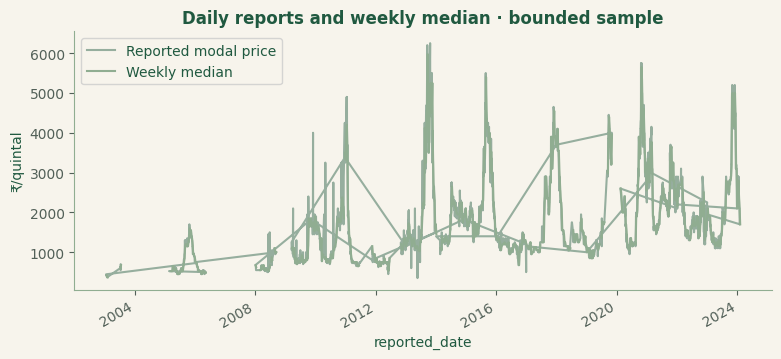

In [3]:
keys = clean.groupby(KEY, observed=True).size().idxmax()
one_market = clean.loc[(clean[KEY].astype("string") == list(keys)).all(axis=1)].set_index("reported_date")
daily = one_market.modal_price_rs_per_quintal
ax = daily.plot(alpha=.45, label="Reported modal price", title="Daily reports and weekly median · bounded sample")
daily.resample("W-SUN").median().plot(ax=ax, label="Weekly median", ylabel="₹/quintal")
ax.legend()
plt.show()

The sample uses the actual cleaning function. Invalid numeric prices, out-of-range modal prices, duplicates and extreme ratios are screened. Missing arrivals stay missing. The saved full audit uses a larger population.

**Takeaway** · Conflicting prices and invalid records are screened before a weekly median is calculated.

**Next** · Use the cleaned observations to build features in Notebook 05.